In [ ]:
# 04 — Preprocesamiento y modelado predictivo

## 1. Objetivo

El objetivo de este notebook es preparar los datos y construir modelos de
Machine Learning capaces de estimar el riesgo de que un cliente sea
clasificado como `BAD = 1`.

El proceso incluirá:

- Separación entre variables predictoras y variable objetivo.
- División de los datos en entrenamiento y prueba.
- Tratamiento de valores ausentes.
- Codificación de variables categóricas.
- Construcción de un pipeline reproducible.
- Creación de un modelo baseline.
- Entrenamiento de modelos de clasificación.
- Evaluación mediante métricas adecuadas para un problema desbalanceado.

El preprocesamiento se realizará evitando utilizar información del conjunto
de prueba durante el entrenamiento, con el objetivo de prevenir data leakage.

In [ ]:
## 2. Importación de librerías y carga de datos

Se importan las librerías necesarias y se carga nuevamente el dataset
original para mantener el notebook independiente y reproducible.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv(r"C:\Users\Sistemas\Desktop\BOOTCAMP DATA\Master Data Sciencie & AI\Proyecto banking\hmeq.csv")


print("Dimensiones:", df.shape)

df.head()

Dimensiones: (5960, 13)


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [ ]:
## 3. Separación de variables predictoras y variable objetivo

La variable `BAD` constituye el objetivo del problema de clasificación:

- `BAD = 0`: cliente no clasificado como incumplidor.
- `BAD = 1`: cliente clasificado como incumplidor.

Se separa la variable objetivo (`y`) del conjunto de variables predictoras
(`X`).

In [3]:
X = df.drop(columns="BAD")
y = df["BAD"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (5960, 12)
Dimensiones de y: (5960,)


In [4]:
y.value_counts(normalize=True).round(4)

BAD
0    0.8005
1    0.1995
Name: proportion, dtype: float64

In [ ]:
## 4. División en entrenamiento y prueba

Los datos se dividen en dos conjuntos:

- **Train (80 %):** utilizado para entrenar el modelo.
- **Test (20 %):** reservado para evaluar el comportamiento del modelo
  sobre observaciones no utilizadas durante el entrenamiento.

Se utiliza una división estratificada para conservar aproximadamente la
proporción de `BAD = 0` y `BAD = 1` en ambos conjuntos.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [6]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDistribución TRAIN:")
print(y_train.value_counts(normalize=True).round(4))

print("\nDistribución TEST:")
print(y_test.value_counts(normalize=True).round(4))

X_train: (4768, 12)
X_test: (1192, 12)

Distribución TRAIN:
BAD
0    0.8005
1    0.1995
Name: proportion, dtype: float64

Distribución TEST:
BAD
0    0.8003
1    0.1997
Name: proportion, dtype: float64


In [ ]:
## 5. Identificación de variables numéricas y categóricas

El dataset contiene variables numéricas y categóricas que requieren
estrategias de preprocesamiento diferentes.

La identificación de las columnas se realiza utilizando únicamente las
variables predictoras.

In [7]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Variables numéricas:")
print(list(numeric_features))

print("\nVariables categóricas:")
print(list(categorical_features))

Variables numéricas:
['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']

Variables categóricas:
['REASON', 'JOB']


In [ ]:
## 6. Tratamiento de valores ausentes

El análisis inicial mostró una presencia relevante de valores ausentes en
varias variables. Además, se observó que la ausencia de información en
determinadas variables estaba asociada descriptivamente con `BAD`.

Por este motivo, los valores ausentes no se eliminarán automáticamente.

Para las variables numéricas se utilizará:

- Imputación mediante la mediana, debido a la presencia de distribuciones
  asimétricas y valores extremos.
- Creación automática de indicadores de ausencia para conservar información
  sobre qué valores estaban originalmente ausentes.

Para las variables categóricas:

- Los valores ausentes se representarán mediante una categoría específica
  denominada `Missing`.
- Posteriormente se aplicará One-Hot Encoding.

Los parámetros necesarios para estas transformaciones se aprenderán
exclusivamente a partir del conjunto de entrenamiento para evitar
data leakage.

In [13]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [14]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [ ]:
Variable numérica
       ↓
¿Tiene NaN?
       ↓
Imputa mediana
       +
Indicador de missing

In [16]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [ ]:
## 8. Construcción del preprocesador

Las transformaciones numéricas y categóricas se integran mediante un
`ColumnTransformer`, permitiendo aplicar automáticamente el tratamiento
adecuado a cada tipo de variable.

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
## 9. Modelo baseline y estrategia de evaluación

Antes de entrenar modelos predictivos es necesario establecer una referencia.

Dado que aproximadamente el 80 % de las observaciones pertenecen a
`BAD = 0`, un clasificador que predijera siempre la clase mayoritaria podría
obtener alrededor de un 80 % de accuracy sin identificar correctamente
ningún cliente `BAD = 1`.

Por este motivo, la evaluación de los modelos no se basará únicamente en
accuracy.

Posteriormente se analizarán métricas como:

- Precision.
- Recall.
- F1-score.
- ROC-AUC.
- Matriz de confusión.

En un problema de riesgo de crédito será especialmente importante analizar
la capacidad del modelo para identificar clientes `BAD = 1`.

In [ ]:
## 10. Regresión logística

Se utiliza una regresión logística como primer modelo predictivo.

Este modelo proporciona un baseline interpretable para un problema de
clasificación binaria y permitirá establecer una referencia antes de
evaluar modelos más complejos.

El preprocesamiento y el clasificador se integran dentro de un único
pipeline para garantizar que las transformaciones se aprendan exclusivamente
a partir de los datos de entrenamiento.

In [18]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [ ]:
## 11. Entrenamiento del modelo

El pipeline completo se entrena utilizando exclusivamente el conjunto de
entrenamiento.

Durante este proceso se aprenden los parámetros necesarios para la imputación,
el escalado y la codificación de las variables, y posteriormente se ajusta
el modelo de regresión logística.

In [19]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
Pipeline
 ├── preprocessor
 │    ├── SimpleImputer
 │    ├── StandardScaler
 │    └── OneHotEncoder
 │
 └── LogisticRegression

In [ ]:
## 12. Predicciones sobre el conjunto de prueba

Una vez entrenado el modelo, se generan predicciones para las observaciones
del conjunto de prueba, que no fueron utilizadas durante el entrenamiento.

In [20]:
y_pred = model.predict(X_test)

y_pred[:20]

array([0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
## 13. Evaluación inicial de la regresión logística

Una vez obtenidas las predicciones, se evalúa el rendimiento del modelo.

Debido al desbalance de la variable objetivo, el análisis no se limita al
accuracy. Se consideran también precision, recall, F1-score y la matriz de
confusión, prestando especial atención a la capacidad para identificar
correctamente los casos `BAD = 1`.

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))

Accuracy : 0.8834
Precision: 0.7676
Recall   : 0.5966
F1-score : 0.6714


In [ ]:
### Interpretación de las métricas

La regresión logística obtiene un accuracy del 88,34 %, aunque esta métrica
debe interpretarse con cautela debido al desbalance de la variable objetivo.

La precision para `BAD = 1` es del 76,76 %, lo que indica que, entre los
clientes clasificados por el modelo como `BAD = 1`, aproximadamente el 77 %
pertenecen realmente a dicha clase.

El recall es del 59,66 %, por lo que el modelo identifica aproximadamente
6 de cada 10 casos `BAD = 1`. En consecuencia, todavía existe una proporción
relevante de clientes de riesgo que el modelo no consigue detectar.

El F1-score es 0,6714 y resume el equilibrio entre precision y recall.

En un problema de riesgo de crédito resulta especialmente importante analizar
el compromiso entre detectar un mayor número de clientes de riesgo y evitar
clasificar incorrectamente como riesgosos a clientes que realmente no lo son.

In [22]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[911,  43],
       [ 96, 142]])

In [ ]:
### Interpretación de la matriz de confusión

La regresión logística clasifica correctamente 911 casos `BAD = 0` y 142 casos
`BAD = 1`.

El modelo genera 43 falsos positivos, correspondientes a clientes clasificados
como `BAD = 1` que realmente pertenecían a la clase 0.

Por otro lado, se observan 96 falsos negativos: clientes que realmente eran
`BAD = 1` pero fueron clasificados como `BAD = 0`. Este tipo de error es
especialmente relevante en un contexto de riesgo de crédito, ya que representa
casos de riesgo que el modelo no ha conseguido detectar.

Por este motivo, además del accuracy, resulta necesario analizar métricas como
precision, recall y F1-score para evaluar adecuadamente el modelo.

In [ ]:
## 14. Evaluación mediante ROC-AUC

Además de las métricas basadas en la clasificación final, se analiza el
ROC-AUC para evaluar la capacidad del modelo para discriminar entre clientes
`BAD = 0` y `BAD = 1`.

Para ello se utilizan las probabilidades estimadas de pertenecer a la clase
`BAD = 1`, en lugar de las predicciones binarias finales.

In [23]:
y_prob = model.predict_proba(X_test)[:, 1]

y_prob[:10]

array([0.01697741, 0.09744288, 0.02090701, 0.25245297, 0.69827494,
       0.14327673, 0.02967123, 0.56517009, 0.01048308, 0.14463236])

In [24]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.9004


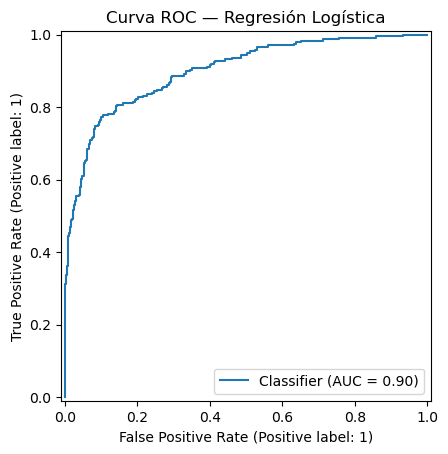

In [25]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("Curva ROC — Regresión Logística")
plt.show()

In [ ]:
### Interpretación del ROC-AUC

La regresión logística obtiene un ROC-AUC de 0,9004, lo que muestra una buena
capacidad para diferenciar entre clientes `BAD = 0` y `BAD = 1`.

Este resultado complementa las métricas anteriores. Aunque el modelo presenta
una buena capacidad general de discriminación, con el criterio de clasificación
actual identifica aproximadamente el 60 % de los clientes `BAD = 1`.

Por tanto, es importante evaluar el modelo utilizando varias métricas y no
únicamente el accuracy.

In [ ]:
## 15. Segundo modelo: Random Forest

Como segundo modelo se utiliza Random Forest, un algoritmo basado en múltiples
árboles de decisión.

A diferencia de la regresión logística, Random Forest puede capturar relaciones
no lineales e interacciones más complejas entre las variables.

El objetivo es comparar posteriormente ambos modelos y analizar cuál presenta
un mejor comportamiento para la identificación de clientes `BAD = 1`.

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [27]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [28]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [29]:
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("F1-score :", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

Accuracy : 0.9044
Precision: 0.8196
Recall   : 0.6681
F1-score : 0.7361
ROC-AUC  : 0.9629


In [30]:
confusion_matrix(y_test, rf_pred)

array([[919,  35],
       [ 79, 159]])

In [ ]:
### Interpretación de Random Forest

Random Forest obtiene un accuracy del 90,44 %, una precision del 81,96 %,
un recall del 66,81 %, un F1-score de 0,7361 y un ROC-AUC de 0,9629.

En comparación con la regresión logística, el modelo presenta mejores
resultados en las métricas analizadas sobre el conjunto de prueba.

También mejora la detección de clientes `BAD = 1`: los falsos negativos
disminuyen de 96 a 79, mientras que los verdaderos positivos aumentan
de 142 a 159.

Estos resultados sugieren que Random Forest captura patrones adicionales
en los datos que la regresión logística no consigue representar con la
misma eficacia.

In [ ]:
## 17. Comparación de modelos

Finalmente, se comparan los resultados obtenidos por la regresión logística
y Random Forest utilizando las principales métricas de clasificación.

Esta comparación permite analizar no solo el porcentaje total de aciertos,
sino también la capacidad de cada modelo para identificar correctamente
los clientes `BAD = 1`.

In [31]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

resultados.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística,0.8834,0.7676,0.5966,0.6714,0.9004
1,Random Forest,0.9044,0.8196,0.6681,0.7361,0.9629


In [ ]:
## 18. Conclusiones

En este notebook se desarrolló el proceso de preprocesamiento y modelado
predictivo del riesgo de crédito.

El preprocesamiento se integró mediante pipelines para evitar data leakage.
Los valores ausentes numéricos se imputaron mediante la mediana conservando
indicadores de ausencia, mientras que las variables categóricas se imputaron
y transformaron mediante One-Hot Encoding.

Se entrenaron dos modelos de clasificación: regresión logística y Random
Forest.

La regresión logística obtuvo un ROC-AUC de 0,9004 y un recall del 59,66 %
para la clase `BAD = 1`.

Random Forest obtuvo un ROC-AUC de 0,9629 y un recall del 66,81 %, además de
mejorar las restantes métricas observadas en el conjunto de prueba. Los falsos
negativos disminuyeron de 96 a 79.

Por tanto, los resultados obtenidos en esta partición muestran que Random
Forest presenta un comportamiento más favorable para continuar el análisis.

El siguiente paso será profundizar en la evaluación del modelo y analizar
qué variables contribuyen en mayor medida a sus predicciones.